# Análise Exploratória de Dados (EDA) - Olist E-Commerce

Neste notebook realizamos:
1. **Verificação de arquivos disponíveis** no bucket S3 (camada `bronze`).
2. **Carregamento dos dados em formato Parquet** utilizando as funções do módulo `src.utils` (`iniciar_cessao_aws`, `listar_arquivos_s3` e `carregar_parquet_s3`).
3. **Inspeção de estrutura, dimensões e tipos de dados** de cada tabela.
4. **Exploração inicial e qualidade dos dados** (valores ausentes, duplicados e amostras).

## 1. Configuração do Ambiente e Conexão AWS S3

In [ ]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
from dotenv import load_dotenv, find_dotenv

# Configurações do pandas para melhor visualização
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

# Adiciona raiz do projeto ao sys.path para importar src.utils
notebook_dir = Path.cwd().resolve()
project_root = notebook_dir.parents[1] if notebook_dir.name == 'notebooks' else notebook_dir.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils import iniciar_cessao_aws, carregar_parquet_s3, listar_arquivos_s3

# Carrega variáveis do .env
load_dotenv(find_dotenv())
BUCKET_NAME = os.getenv('BUCKET_NAME')
AWS_REGION = os.getenv('AWS_REGION', 'us-east-1')

# Inicializa sessão e cliente S3
session = iniciar_cessao_aws()
s3_client = session.client('s3')

print(f" Conectado ao S3!")
print(f" - Bucket: {BUCKET_NAME}")
print(f" - Região: {AWS_REGION}")

✅ Conectado ao S3!
   - Bucket: postech-challenge-datascience-004
   - Região: us-east-1


## 2. Verificar Todos os Arquivos Parquet Disponíveis no S3

In [2]:
# Lista todos os arquivos na camada bronze usando listar_arquivos_s3 de utils
arquivos_bronze = listar_arquivos_s3(s3_client, BUCKET_NAME, prefixo='bronze/')

# Cria DataFrame de resumo dos arquivos disponíveis
lista_resumo = []
for chave in arquivos_bronze:
    obj_meta = s3_client.head_object(Bucket=BUCKET_NAME, Key=chave)
    nome_arquivo = Path(chave).name
    nome_tabela = Path(chave).stem
    tamanho_mb = obj_meta['ContentLength'] / (1024 * 1024)
    modificado = obj_meta['LastModified'].strftime('%Y-%m-%d %H:%M:%S')
    lista_resumo.append({
        'Tabela': nome_tabela,
        'Arquivo': nome_arquivo,
        'Chave S3': chave,
        'Tamanho (MB)': round(tamanho_mb, 2),
        'Última Modificação': modificado
    })

df_catalogo = pd.DataFrame(lista_resumo)
print(f"Total de arquivos Parquet encontrados na camada Bronze: {len(df_catalogo)}\n")
display(df_catalogo[['Tabela', 'Tamanho (MB)', 'Última Modificação']])

Total de arquivos Parquet encontrados na camada Bronze: 9



,Tabela,Tamanho (MB),Última Modificação
0,olist_customers_dataset,6.68,2026-10-24 19:09:17
1,olist_geolocation_dataset,16.24,2026-10-24 19:09:19
2,olist_order_items_dataset,6.24,2026-10-24 19:09:20
3,olist_order_payments_dataset,3.66,2026-10-24 19:09:21
4,olist_order_reviews_dataset,9.16,2026-10-24 19:09:22
5,olist_orders_dataset,10.28,2026-10-24 19:09:23
6,olist_products_dataset,1.34,2026-10-24 19:09:25
7,olist_sellers_dataset,0.13,2026-10-24 19:09:25
8,product_category_name_translation,0.00,2026-10-24 19:09:25


## 3. Carregamento dos Parquets via `carregar_parquet_s3`

Podemos carregar individualmente qualquer tabela com:
```python
df = carregar_parquet_s3(s3_client, BUCKET_NAME, nome_tabela='olist_customers_dataset', camada='bronze')
```
Ou carregar todas as tabelas em um dicionário para exploração unificada.

In [3]:
# Dicionário com todos os DataFrames carregados do S3
dfs = {}

for item in lista_resumo:
    tabela = item['Tabela']
    # Carrega utilizando a função do utils
    dfs[tabela] = carregar_parquet_s3(
        s3_client=s3_client,
        bucket=BUCKET_NAME,
        nome_tabela=tabela,
        camada='bronze'
    )

print(f"\n🎉 {len(dfs)} tabelas carregadas com sucesso na memória!")

Lendo: s3://postech-challenge-datascience-004/bronze/olist_customers_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_geolocation_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_order_items_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_order_payments_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_order_reviews_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_orders_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_products_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_sellers_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/product_category_name_translation.parquet

🎉 9 tabelas carregadas com sucesso na memória!


## 4. Visão Geral das Dimensões e Metadados das Tabelas

In [4]:
# Tabela comparativa de dimensões e contagem de nulos
info_tabelas = []
for nome, df in dfs.items():
    n_nulos = df.isna().sum().sum()
    mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
    info_tabelas.append({
        'Tabela': nome,
        'Qtd Linhas': df.shape[0],
        'Qtd Colunas': df.shape[1],
        'Total Nulos': n_nulos,
        'Memória (MB)': round(mem_mb, 2)
    })

df_info = pd.DataFrame(info_tabelas)
display(df_info)

,Tabela,Qtd Linhas,Qtd Colunas,Total Nulos,Memória (MB)
0,olist_customers_dataset,99441,5,0,11.03
1,olist_geolocation_dataset,1000163,5,0,50.12
2,olist_order_items_dataset,112650,7,0,18.37
3,olist_order_payments_dataset,103886,5,0,8.11
4,olist_order_reviews_dataset,99224,7,145903,17.84
5,olist_orders_dataset,99441,8,4908,21.95
6,olist_products_dataset,32951,9,2448,3.73
7,olist_sellers_dataset,3095,4,0,0.22
8,product_category_name_translation,71,2,0,0.00


## 5. Inspeção Inicial das Tabelas Principais

In [5]:
# 1. Clientes
print("=== olist_customers_dataset ===")
display(dfs['olist_customers_dataset'].head(3))

# 2. Pedidos
print("=== olist_orders_dataset ===")
display(dfs['olist_orders_dataset'].head(3))

# 3. Itens do Pedido
print("=== olist_order_items_dataset ===")
display(dfs['olist_order_items_dataset'].head(3))

# 4. Pagamentos
print("=== olist_order_payments_dataset ===")
display(dfs['olist_order_payments_dataset'].head(3))

# 5. Produtos
print("=== olist_products_dataset ===")
display(dfs['olist_products_dataset'].head(3))

=== olist_customers_dataset ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


=== olist_orders_dataset ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


=== olist_order_items_dataset ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


=== olist_order_payments_dataset ===


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71


=== olist_products_dataset ===


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


## EDA reviews

In [11]:
df_review = dfs['olist_order_reviews_dataset']

print("Distribuição avaliações dos pedidos:")
display(df_review['review_score'].value_counts(dropna=False))


Distribuição avaliações dos pedidos:


review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64

In [13]:
list(df_review.columns)

['review_id',
 'order_id',
 'review_score',
 'review_comment_title',
 'review_comment_message',
 'review_creation_date',
 'review_answer_timestamp']

In [12]:
df_review.head(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [71]:
#filtrando apenas o que for relevante para o modelo num primeiro momento: 
mensagens  = df_review[['review_score','review_comment_message',]]

mapa_avaliacoes = {
    1: "negativa",
    2: "negativa",
    3: "negativa",
    4: "positiva",
    5: "positiva"
}

# Criando a nova coluna
mensagens["avaliacao"] = mensagens["review_score"].map(mapa_avaliacoes)
mensagens = mensagens.dropna(subset=["review_comment_message"])
mensagens = mensagens.drop(columns=["review_score"])
print(mensagens)

                                  review_comment_message avaliacao
3                  Recebi bem antes do prazo estipulado.  positiva
4      Parabéns lojas lannister adorei comprar pela I...  positiva
9      aparelho eficiente. no site a marca do aparelh...  positiva
12       Mas um pouco ,travando...pelo valor ta Boa.\r\n  positiva
15     Vendedor confiável, produto ok e entrega antes...  positiva
...                                                  ...       ...
99205  para este produto recebi de acordo com a compr...  positiva
99208  Entregou dentro do prazo. O produto chegou em ...  positiva
99215  O produto não foi enviado com NF, não existe v...  negativa
99221  Excelente mochila, entrega super rápida. Super...  positiva
99223  meu produto chegou e ja tenho que devolver, po...  negativa

[40977 rows x 2 columns]


In [47]:
mensagens.isna().sum()

review_comment_message    0
sentimento                0
dtype: int64

In [51]:
#Verificando o tamanho da base atual menos a diferença dos nulos 
print(f'base inicia {df_review.shape[0] }')
print(f'mensagem após limpeza {mensagens.shape[0]}')
print(f'nulos : {df_review['review_comment_message'].isna().sum()}')
print('diferença ')
df_review.shape[0] - mensagens.shape[0] - df_review['review_comment_message'].isna().sum()

base inicia 99224
mensagem após limpeza 40977
nulos : 58247
diferença 


np.int64(0)

In [52]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def nuvem_palavras(texto,coluna_texto,avaliacao):
    texto_avaliacao = texto.query(f"avaliacao == '{avaliacao}'")[coluna_texto]

    texto_unido = ' '.join(texto_avaliacao)
    nuvem_palavras =  WordCloud(width=800,height=500,max_font_size=110,collocations=False).generate(texto_unido)
    
    plt.figure(figsize=(10,7))
    plt.imshow(nuvem_palavras,interpolation='bilinear')
    plt.axis('off')
    plt.show()


palavras mais usadas positivo e negativo: 

negativa


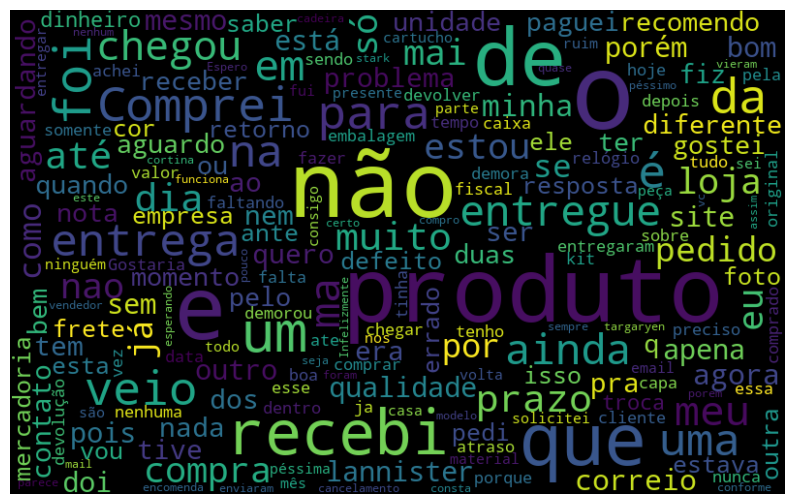

postiva


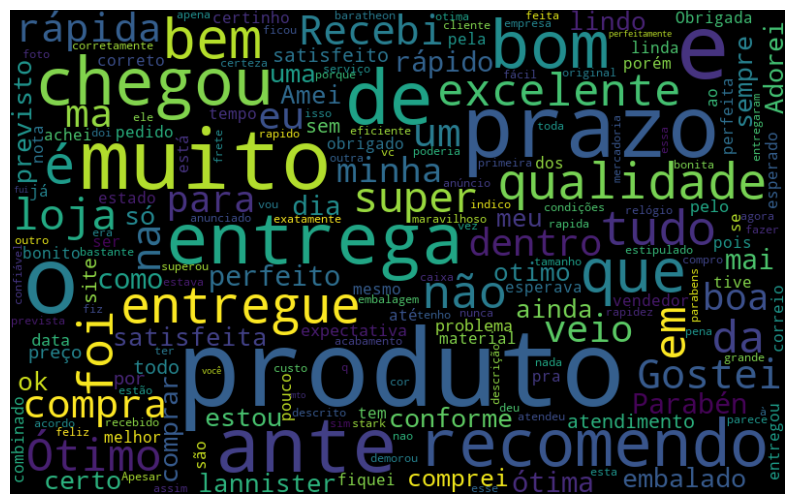

In [57]:
print('negativa')
nuvem_palavras(mensagens,'review_comment_message','negativa')
print('postiva')
nuvem_palavras(mensagens,'review_comment_message','positiva')

Vou usara agora a biblioteca NLTK para fazer a limpeza dos textos, stopwords, pontuação etc

In [72]:
mensagens = mensagens.rename(columns={'review_comment_message': 'review'})

In [60]:
import nltk

#para baixar 
#nltk.download('all')

In [73]:
from nltk import tokenize

#calcular frequencia da aparição das palavras

token_espaco = tokenize.WhitespaceTokenizer()


todas_palavras = ' '.join([texto for texto in mensagens.review])
token_frase = token_espaco.tokenize(todas_palavras)

frequencia = nltk.FreqDist(token_frase)

avaliação de palavras mais usadas

In [ ]:
df_frequencia = pd.DataFrame({'Palavra' : list(frequencia.keys()),
                              'Frequencia' : list(frequencia.values())})
df_frequencia

,Palavra,Frequencia
0,Recebi,1324
1,bem,2794
2,antes,5343
3,do,10813
4,prazo,4777
...,...,...
35093,rala...diferente,1
35094,"original,prazo",1
35095,rápido.Super,1
35096,impossivel,1


In [ ]:
import seaborn as sns 

def grafico_frequencia(texto, coluna_texto, quantidade):
    todas_palavras = ' '.join([texto for texto in texto[coluna_texto]])
    token_espaco = tokenize.WhitespaceTokenizer()
    frequencia = nltk.FreqDist(token_espaco.tokenize(todas_palavras))
    df_frequencia = pd.DataFrame({"Palavra": list(frequencia.keys()),                                 "Frequência": list(frequencia.values())})
    df_frequencia = df_frequencia.nlargest(columns="Frequência", n=quantidade)
    plt.figure(figsize=(20,6))
    ax = sns.barplot(data=df_frequencia, x="Palavra", y ="Frequência", color='gray')
    ax.set(ylabel="Contagem")
    plt.show()



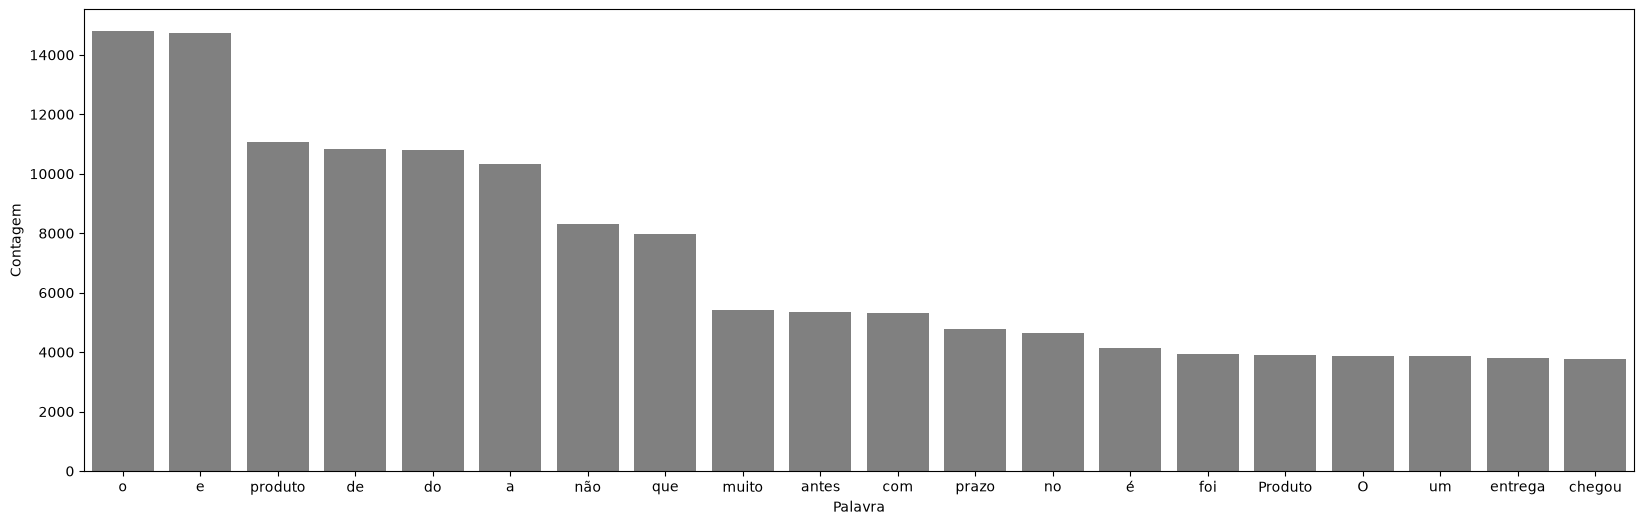

In [100]:
grafico_frequencia(mensagens, 'review', 20)

In [ ]:
#REMOVER AS STOP WORDS

stop_words = nltk.corpus.stopwords.words('portuguese')
len(stop_words)


frase_processada = []

for review in mensagens.review:
    palavra_texto = token_espaco.tokenize(review)
    nova_frase = [palavra for palavra in palavra_texto if palavra not in stop_words]
    frase_processada.append(' '.join(nova_frase))

mensagens['tratamento_1'] = frase_processada

207

In [ ]:
#REMOVER PONTUAÇÃO

token_pontuacao = tokenize.WordPunctTokenizer()
frase_processada = []

for review in mensagens['tratamento_1']:
    palavras_texto = token_pontuacao.tokenize(review)
    nova_frase = [palavra for palavra in palavras_texto if 
    palavra.isalpha() and palavra not in stop_words]  #isalpha serve para pegar palavras do alfabeto
    frase_processada.append(' '.join(nova_frase))

mensagens['tratamento_2'] = frase_processada

In [91]:
#remover acentos

import unidecode

sem_acentos = [unidecode.unidecode(texto) for texto in mensagens['tratamento_2']]
stopwords_sem_acento = [unidecode.unidecode(texto) for texto in stop_words]

In [92]:
mensagens['tratamento_3'] = sem_acentos

frase_processada = []

for avaliacao in mensagens['tratamento_3']:
    palavras_texto = token_pontuacao.tokenize(avaliacao)
    nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
    frase_processada.append(' '.join(nova_frase))


mensagens['tratamento_3'] = frase_processada


In [ ]:
#Transformar em Lower Case

frase_processada = []

for opiniao in mensagens['tratamento_3']:
    opiniao = opiniao.lower()
    palavras_texto = token_pontuacao.tokenize(opiniao)
    nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
    frase_processada.append(' '.join(nova_frase))

mensagens['tratamento_4'] = frase_processada

In [96]:
mensagens.head(2).T

,3,4
review,Recebi bem antes do prazo estipulado.,Parabéns lojas lannister adorei comprar pela I...
avaliacao,positiva,positiva
tratamento_1,Recebi bem antes prazo estipulado.,Parabéns lojas lannister adorei comprar Intern...
tratamento_2,Recebi bem antes prazo estipulado,Parabéns lojas lannister adorei comprar Intern...
tratamento_3,Recebi bem antes prazo estipulado,Parabens lojas lannister adorei comprar Intern...
tratamento_4,recebi bem antes prazo estipulado,parabens lojas lannister adorei comprar intern...


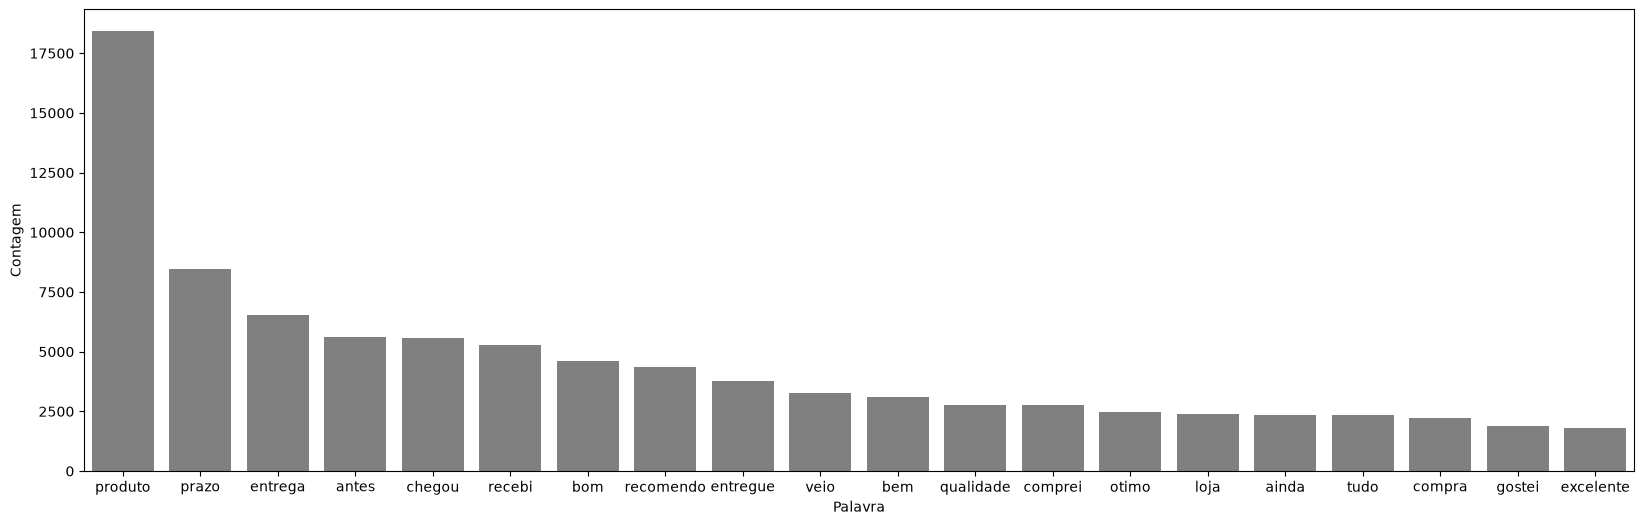

In [101]:
grafico_frequencia(mensagens, 'tratamento_4', 20)